In [1]:
from ModelSimlink import RadiativeTransitions, Levels
from standard_imports import *
from loaders import index
from plots import adv_plt, splt, interactive
from scipy.optimize import curve_fit
from Tools import LinesManipulator

Call %matplotlib widget
Remember to select "cambiare presentazione" -> "application" in the cells output when you want interactive mode


In [2]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

In [3]:
calib_base = pd.read_csv('CalibrationData/Calib_20250204_FCUVIR600.csv', index_col = False).to_dict('list')

In [4]:
worker = LinesManipulator.LinesManipulator()

In [5]:
for d in data:
        d['wl_realigned'] = worker.realign_wl( d['avantes']['wl'], d['avantes']['int'] )
        d['int_withoutbaseline'] = worker.remove_baseline( d['avantes']['int'] )
        d['cal'] = worker.estimate_calibration( d['wl_realigned'], d['int_withoutbaseline'], calib_base, all_lines = RadiativeTransitions.RadiativeTransitions().linesList() )
        d['int_calibrated'] = d['cal']['int_calib']
        d['densities'] = worker.estimate_densities( d['wl_realigned'], d['int_calibrated'], RadiativeTransitions.RadiativeTransitions().linesList() )

Realigned with y = -0.00x^2 +1.00x -0.26
Initializing class Levels
Realigned with y = -0.00x^2 +1.00x -0.22
Realigned with y = -0.00x^2 +1.00x -0.19
Realigned with y = 0.00x^2 +1.00x -0.10
Realigned with y = -0.00x^2 +1.00x -0.18
Realigned with y = 0.00x^2 +1.00x -0.15
Realigned with y = -0.00x^2 +1.00x -0.16
Realigned with y = 0.00x^2 +1.00x -0.12
Realigned with y = 0.00x^2 +1.00x +0.96
Realigned with y = 0.00x^2 +1.00x +1.33
Realigned with y = 0.00x^2 +1.00x +1.24
Realigned with y = 0.00x^2 +1.00x +0.91
Realigned with y = 0.00x^2 +1.00x +0.90
Realigned with y = 0.00x^2 +1.00x +1.24
Realigned with y = 0.00x^2 +1.00x +0.99
Realigned with y = 0.00x^2 +1.00x +0.99
Realigned with y = 0.00x^2 +1.00x +1.17
Realigned with y = 0.00x^2 +1.00x +0.94
Realigned with y = -0.00x^2 +1.00x +0.21
Realigned with y = -0.00x^2 +1.00x +0.45


In [6]:

lv = Levels.Levels()

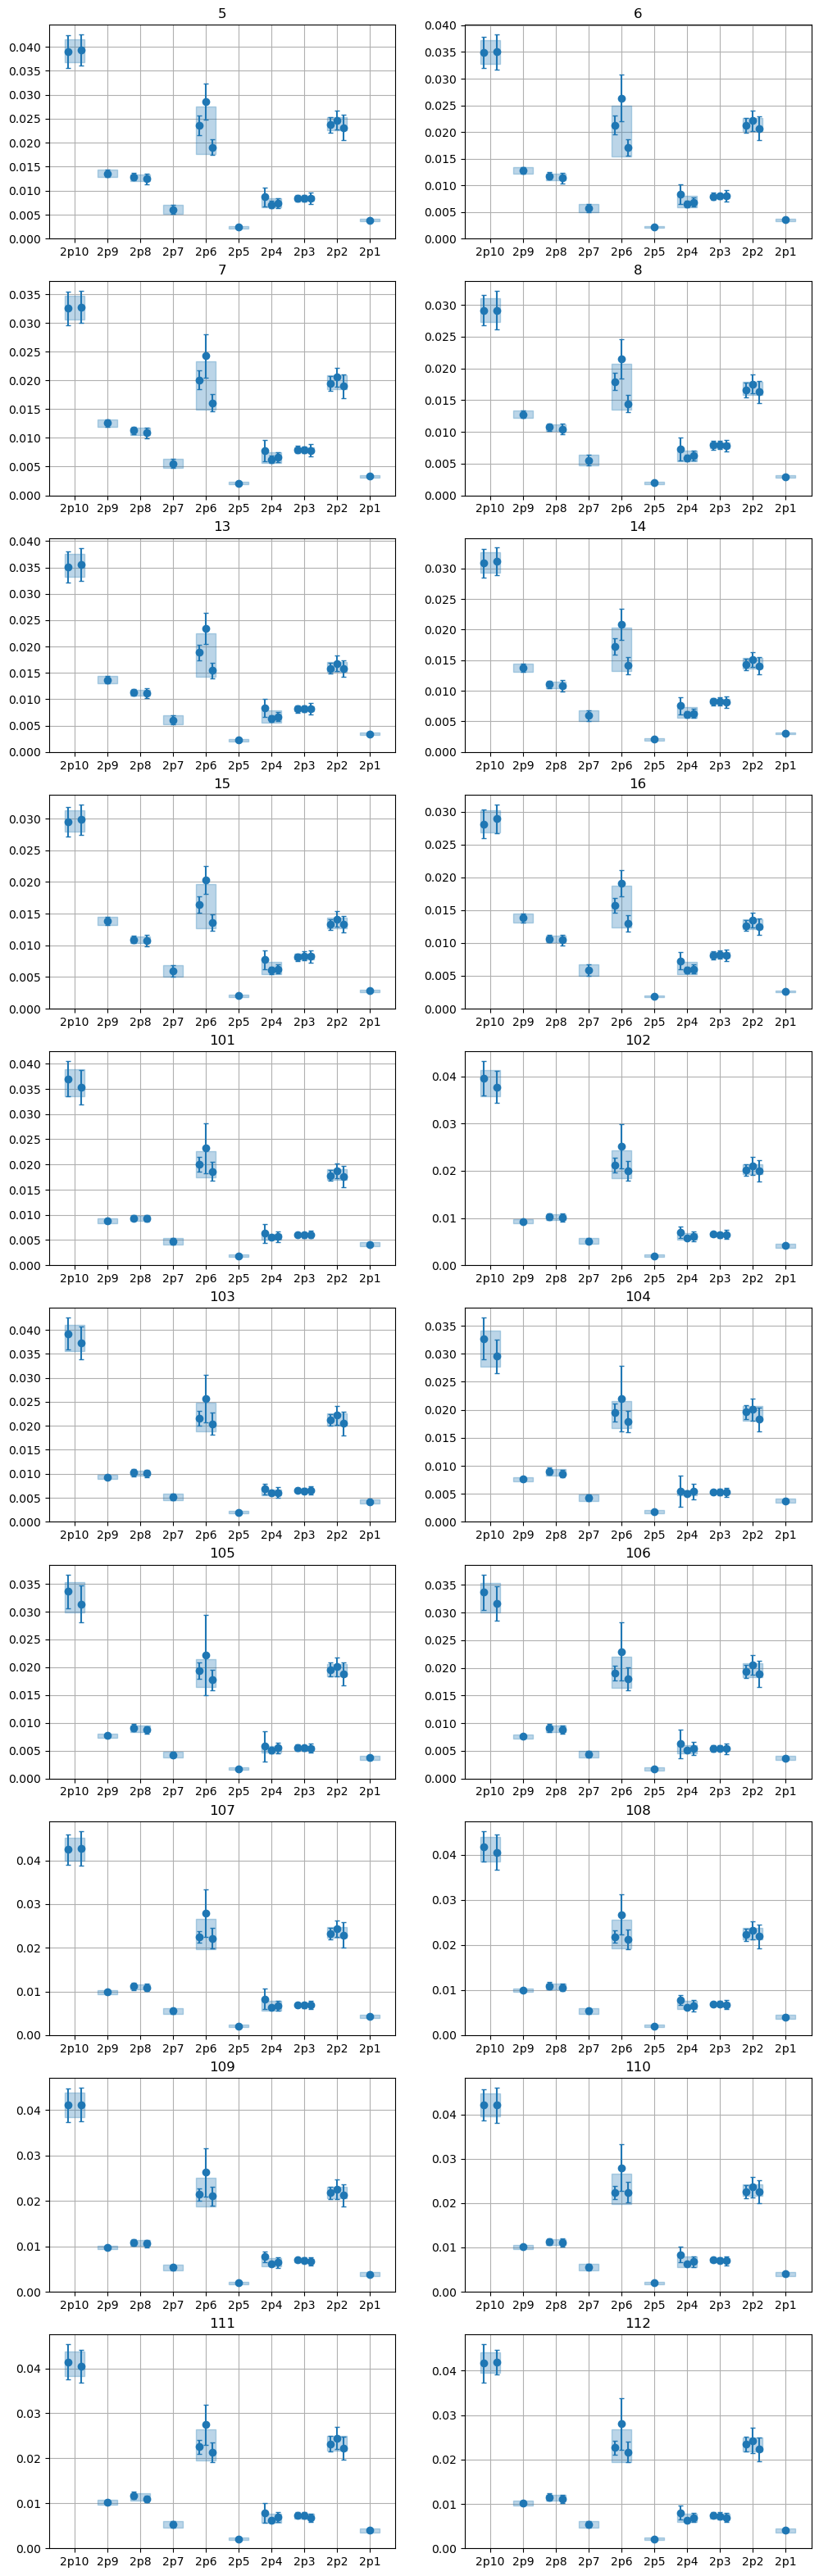

In [8]:
splt.init_bytot( len( data ), cols = 2 )
for d in data:
    splt.next()

    for (k,v) in d['densities'].items():
        i = lv.ID( k )
        plt.fill_between( [ i - 0.3, i + 0.3 ], np.array([1,1]) * v['avg'].n - v['avg'].s, np.array([1,1]) *  v['avg'].n + v['avg'].s, color = 'tab:blue', alpha = 0.3 )
        xs = np.linspace( i - 0.2, i + 0.2, len( v['all'] ) )
        if( len( v['all'] ) == 1 ):
            xs = [ i ]
        plt.plot( xs, v['all'], fmt = 'o', color = 'tab:blue' )

    plt.xticks( np.arange( 5, 15 ), [ lv.name( i ) for i in range( 5,15 ) ] )
    plt.ylim( bottom = 0 )

    plt.title(d['ID'])

In [9]:
for d in data:
    pd.DataFrame.from_dict({
        'level': d['densities'].keys(),
        'density_n': [ d['densities'][k]['avg'].n for k in d['densities'].keys() ],
        'density_s': [ d['densities'][k]['avg'].s for k in d['densities'].keys() ]
    }).to_csv( f"Densities/{d['ID']:03d}.csv", index=False )